# 2. Feature engineering and model training

This notebook repeats the model comparison defined in `src/train.py` using the same stratified 80/20 split, seed 42, and five-fold cross-validation. I use it as a readable walkthrough and compare its selected model with `models/metrics.json`. The notebook does not overwrite the saved model or the MLflow run store.


In [1]:
%matplotlib inline
from IPython.display import display
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
%matplotlib inline
print("working dir:", Path.cwd())

working dir: C:\Users\Dinesh\Downloads\heart-mlops-submission\heart-mlops-final


In [2]:
import json, joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from src.features import RAW_FEATURES, build_pipeline, feature_names
from src.train import GRIDS, SEED, SCORING, holdout_metrics
df = pd.read_csv('data/heart_cleaned.csv')
X, y = df[RAW_FEATURES], df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(len(X_train), len(X_test))

2026/10/20 14:38:28 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Dinesh\Downloads\heart-mlops-submission\heart-mlops-final\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


242 61


## Preprocessing pipeline

Imputation, scaling, and one-hot encoding are kept inside the scikit-learn `Pipeline` instead of being performed on the entire dataset in advance. This matters because each cross-validation fold should learn its own preprocessing values from its training portion. The saved pipeline is also used by the API, which keeps inference transformations consistent with training.


In [3]:
pipe = build_pipeline(GRIDS['logreg'][0])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...00240525CDEE0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary 

## Model search

I compare three Logistic Regression settings with six Random Forest settings. The grids are deliberately small because there are only about 240 records in the training split; an extensive search could spend more effort fitting noise than finding a model that generalises. The candidates are ranked by their mean cross-validation ROC-AUC, while accuracy, precision, and recall are recorded for context.


In [4]:
rows, fitted = [], {}
for name, (est, grid) in GRIDS.items():
    from sklearn.model_selection import ParameterGrid
    for params in ParameterGrid(grid):
        p = build_pipeline(clone(est).set_params(**params))
        s = cross_validate(p, X_train, y_train, cv=cv, scoring=SCORING)
        p.fit(X_train, y_train)
        label = f'{name}-' + '-'.join(f'{k}{v}' for k, v in params.items())
        fitted[label] = p
        rows.append({'run': label, **{f'cv_{m}': s[f'test_{m}'].mean() for m in SCORING},
                     'cv_auc_std': s['test_roc_auc'].std(),
                     'test_auc': holdout_metrics(y_test, p.predict_proba(X_test)[:, 1], 0.5)['roc_auc']})
res = pd.DataFrame(rows).sort_values('cv_roc_auc', ascending=False).round(3)
res

,run,cv_accuracy,cv_precision,cv_recall,cv_roc_auc,cv_auc_std,test_auc
1,logreg-C0.3,0.847,0.877,0.783,0.904,0.016,0.970
2,logreg-C3.0,0.847,0.877,0.783,0.902,0.014,0.963
4,random_forest-max_depth3-min_samples_leaf4,0.822,0.849,0.755,0.895,0.023,0.950
8,random_forest-max_depthNone-min_samples_leaf4,0.826,0.846,0.774,0.894,0.025,0.947
6,random_forest-max_depth6-min_samples_leaf4,0.830,0.847,0.783,0.894,0.026,0.946
3,random_forest-max_depth3-min_samples_leaf1,0.826,0.860,0.755,0.893,0.024,0.947
0,logreg-C0.03,0.814,0.866,0.711,0.888,0.023,0.964
5,random_forest-max_depth6-min_samples_leaf1,0.822,0.845,0.764,0.879,0.026,0.949
7,random_forest-max_depthNone-min_samples_leaf1,0.814,0.810,0.783,0.876,0.037,0.948


In [5]:
saved = json.load(open('models/metrics.json'))
best = res.iloc[0]
print('notebook winner :', best['run'], best['cv_roc_auc'])
print('saved winner    :', saved['best_run'], round(saved['cv_metrics']['roc_auc'], 3))
assert best['run'] == saved['best_run']

notebook winner : logreg-C0.3 0.904
saved winner    : logreg-C0.3 0.904


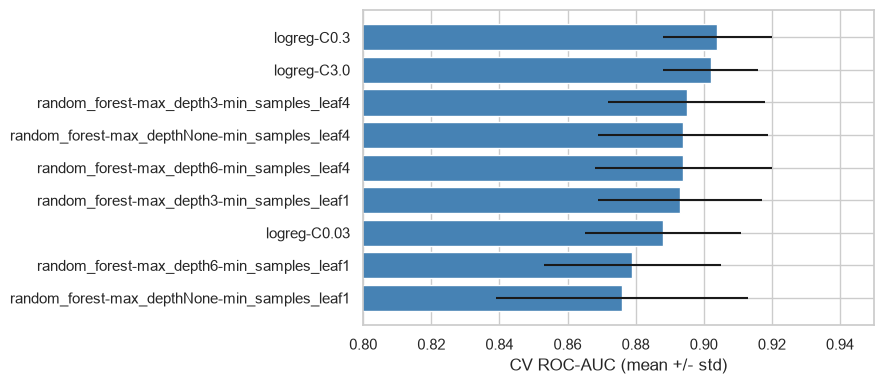

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
r = res.sort_values('cv_roc_auc')
ax.barh(r['run'], r['cv_roc_auc'], xerr=r['cv_auc_std'], color='steelblue')
ax.set_xlim(0.8, 0.95); ax.set_xlabel('CV ROC-AUC (mean +/- std)'); fig.tight_layout(); display(fig)

## Selected model: evaluation and threshold choice

After choosing the best configuration from cross-validation, I load the saved model bundle and evaluate it on the held-out test split. I report the default 0.5 threshold as a baseline, then show what happens when the threshold is lowered to favour recall. The held-out test results are for reporting only; they are not used to select the model or threshold.


In [7]:
bundle = joblib.load('models/model.joblib')
print(bundle.keys(), bundle['threshold'], bundle['features'])
pl, thr = bundle['pipeline'], bundle['threshold']
proba = pl.predict_proba(X_test)[:, 1]
pd.DataFrame({'t=0.5': holdout_metrics(y_test, proba, 0.5),
              f't={thr}': holdout_metrics(y_test, proba, thr)}).round(3)

dict_keys(['pipeline', 'threshold', 'features']) 0.26 ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


,t=0.5,t=0.26
accuracy,0.902,0.836
precision,0.867,0.737
recall,0.929,1.000
roc_auc,0.970,0.970


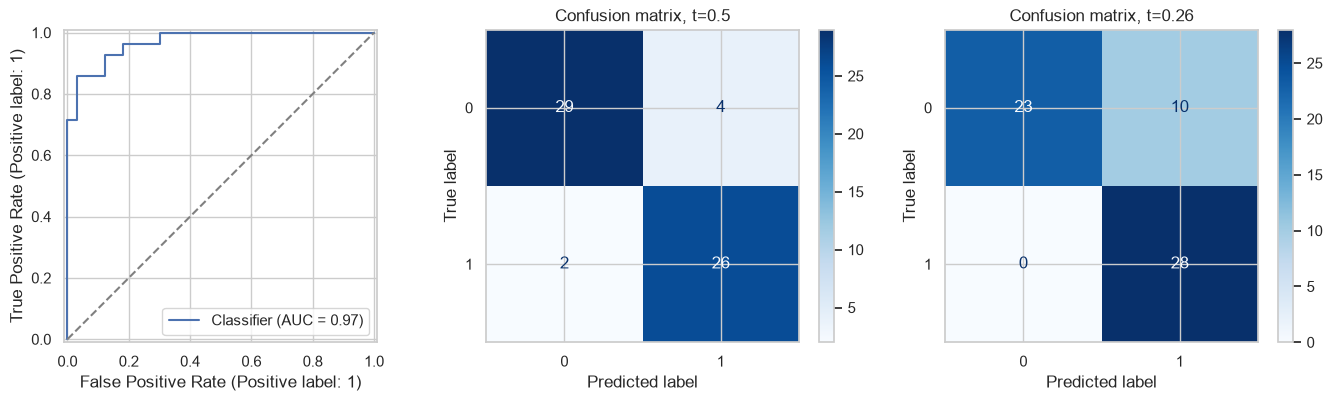

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0]); axes[0].plot([0,1],[0,1],'--',c='grey')
for ax, t in zip(axes[1:], (0.5, thr)):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= t).astype(int), ax=ax, cmap='Blues')
    ax.set_title(f'Confusion matrix, t={t}')
fig.tight_layout(); display(fig)

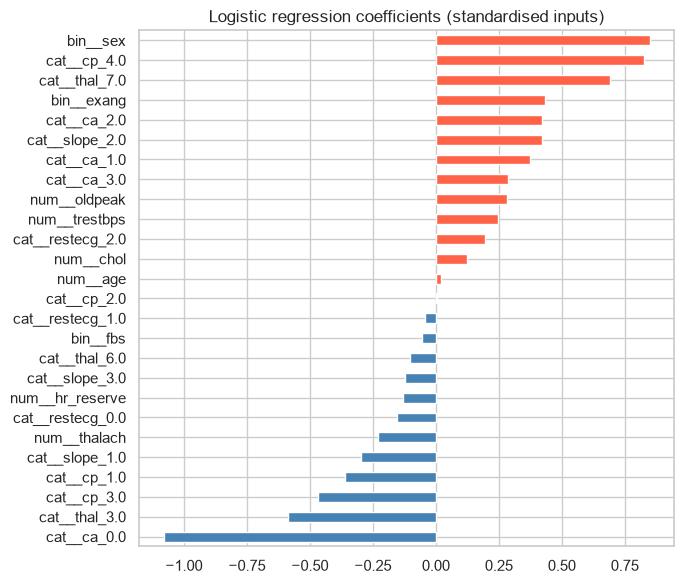

In [9]:
coef = pd.Series(pl.named_steps['model'].coef_[0], index=feature_names(pl)).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
coef.plot.barh(ax=ax, color=['tomato' if v > 0 else 'steelblue' for v in coef])
ax.set_title('Logistic regression coefficients (standardised inputs)'); fig.tight_layout(); display(fig)

The threshold of 0.26 was selected using out-of-fold predictions on the training split to meet the target recall of at least 90%. I did not tune it against the held-out test labels. On this small test split, the lower threshold catches more positive cases but also creates more false positives, so the trade-off needs to be stated alongside the headline recall.
